# seq2PRINT: TF binding from sequence, per cell type

[PRINT](t_print_footprint.ipynb) reads footprints off measured Tn5 cuts,
so it needs many cuts at every site. **seq2PRINT** (from
[scPrinter](https://github.com/buenrostrolab/scPrinter)) learns to predict
those footprints from DNA sequence. A dilated CNN reads 1,840 bp and
predicts PRINT's footprint score at 99 sizes over the central 800 bp, plus
the window's coverage. LoRA then adapts one trained model to each cell
type, and the model's attributions give a TF binding score at every base,
in every cell type, including sites with few cuts.

This tutorial follows scPrinter's PBMC tutorial on the 10x PBMC 10k
Multiome sample:

1. group cells into seven cell types and call peaks in each;
2. train one bulk model on all cells;
3. fine-tune one LoRA state per cell type;
4. score TF binding at marker-gene promoters in every cell type;
5. compare binding of CEBPA, SPI1, PAX5, RUNX3 and other TFs between cell
   types at their motif sites.

```python
model = s2p.build_seq2print()                                        # scPrinter's architecture
data  = s2p.Seq2PRINTDataset(peaks, fasta=..., reader=..., bias=..., groups=...)
model = s2p.fit(model, data.split(train), data.split(valid)).model
model.add_lora(celltype_embeddings, coverages=...)                    # one state per cell type
tfbs  = s2p.tf_binding(model, s2p.one_hot_regions(fasta, regions), states=[0, 1, ...])
```

`tf_binding` is scPrinter's sequence TF binding score: DeepLIFT/SHAP
attributions of the model (computed through gReLU, `epi.models.grelu`)
are fed to scPrinter's published TF-binding networks. The network blocks
and training targets are scPrinter's, so trained weights load in either
package.

## Part 1 · Setup

In [1]:
%matplotlib inline
import os, sys, pathlib, re, copy, warnings
warnings.filterwarnings('ignore', module='tqdm')
warnings.filterwarnings('ignore', message='.*torch.jit.load.*')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad
import scanpy as sc
import torch


def _find_repo(start):
    p = pathlib.Path(start).resolve()
    for cand in (p, *p.parents):
        if (cand / 'epione' / '__init__.py').exists():
            return cand
    return None


CODE = (pathlib.Path(os.environ['EPIONE_SRC']) if os.environ.get('EPIONE_SRC')
        else _find_repo(pathlib.Path.cwd()))
if CODE is not None:
    sys.path.insert(0, str(CODE))

import epione as epi
from epione._insertions import InsertionReader
s2p = epi.models.seq2print

# EPIONE_TUTORIAL_DATA picks the folder; the default is epione's pooch cache.
DATA = os.environ.get('EPIONE_TUTORIAL_DATA')
files = epi.datasets.pbmc10k_multiome_atac(pathlib.Path(DATA) / 'pbmc10k_multiome' if DATA else None)
FASTA = str(epi.data.hg38.fasta)                      # GENCODE GRCh38, downloaded once
WORK = files['fragments'].parent / 'seq2print_work'; WORK.mkdir(exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

epi.pl.plot_set()

device: cuda NVIDIA H100 80GB HBM3


└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Part 2 · Cell types

scGLUE's copy of this sample carries Seurat-WNN cell types (from RNA and
ATAC together). We merge them into seven groups, each with enough cells
for a cell-type model, and drop the small T-cell subsets (MAIT, γδ T) and
progenitors. The iterative LSI embedding of the peak matrix gives each
cell type its LoRA embedding later.

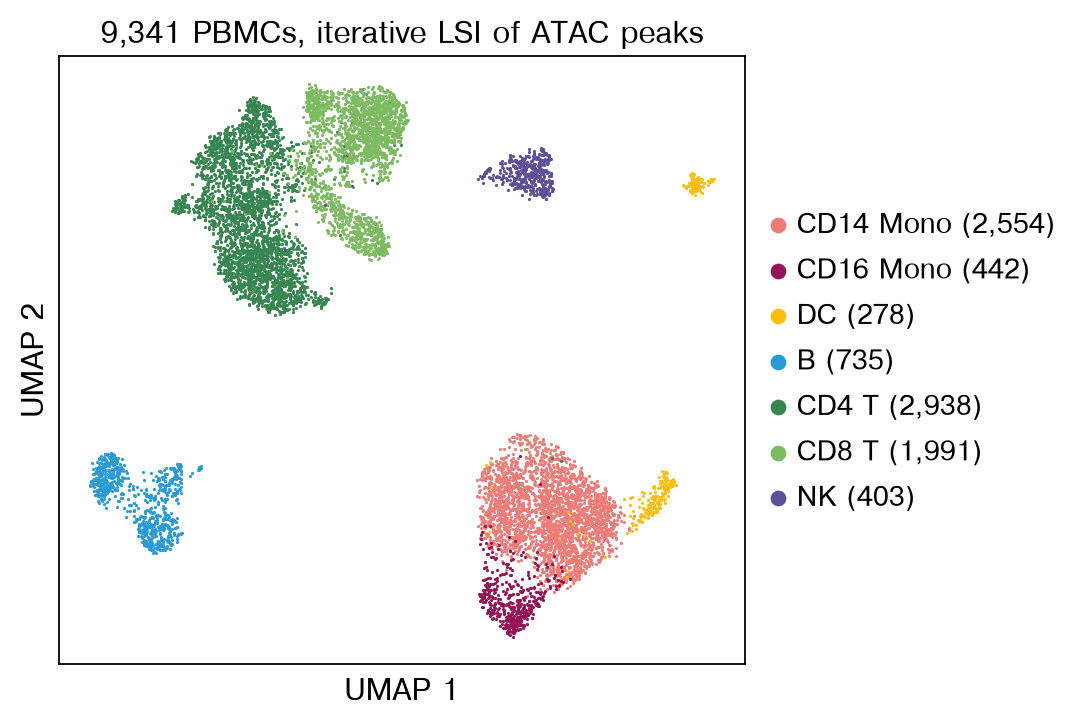

CPU times: user 2min 32s, sys: 5.6 s, total: 2min 38s
Wall time: 1min


In [2]:
%%time
COARSE = {'CD14 Mono': 'CD14 Mono', 'CD16 Mono': 'CD16 Mono', 'cDC': 'DC', 'pDC': 'DC',
          'Naive B': 'B', 'Intermediate B': 'B', 'Memory B': 'B', 'Plasma': 'B',
          'CD4 Naive': 'CD4 T', 'CD4 TCM': 'CD4 T', 'CD4 TEM': 'CD4 T', 'Treg': 'CD4 T',
          'CD8 Naive': 'CD8 T', 'CD8 TEM_1': 'CD8 T', 'CD8 TEM_2': 'CD8 T', 'NK': 'NK'}
TYPES = ['CD14 Mono', 'CD16 Mono', 'DC', 'B', 'CD4 T', 'CD8 T', 'NK']
# the same colour per cell type as t_print_footprint (from epi.pl.sc_color)
TCOL = dict(zip(TYPES, ['#EF7B77', '#941456', '#FCBC10', '#279AD7', '#368650', '#7CBB5F', '#5E4D9A']))

atac = ad.read_h5ad(files['atac'])
atac.obs['celltype'] = atac.obs['cell_type'].map(COARSE)
atac = atac[atac.obs['celltype'].notna()].copy()
atac.obs['celltype'] = pd.Categorical(atac.obs['celltype'], TYPES)
atac.uns['files'] = {'fragments': str(files['fragments'])}
sc.settings.verbosity = 0                              # keep scanpy's progress lines out
epi.tl.iterative_lsi(atac, n_components=30, verbose=False)
sc.pp.neighbors(atac, use_rep='X_iterative_lsi')
sc.tl.umap(atac)
barcodes = atac.obs_names.tolist()
ct = atac.obs['celltype'].to_numpy()

fig, ax = plt.subplots(figsize=(5.5, 5))
for t in TYPES:
    xy = atac.obsm['X_umap'][ct == t]
    ax.scatter(xy[:, 0], xy[:, 1], s=2, lw=0, color=TCOL[t], label=f'{t} ({len(xy):,})', rasterized=True)
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2')
ax.legend(markerscale=5, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_title(f'{len(atac):,} PBMCs, iterative LSI of ATAC peaks')
plt.show()

## Part 3 · Peaks per cell type

scPrinter trains seq2PRINT on summit-centred peaks. `epi.single.call_peaks`
calls peaks in each cell type and merges them into one set of 500-bp
peaks around summits, labelled with the cell type that called each one
most strongly, so peaks open only in a small cell type are not lost.

The split is **scPrinter's fold 0 for hg38**: whole chromosomes for
training, validation and test (chr1, chr3, chr6), so no test window shares
sequence with training.

In [3]:
%%time
peak_file = WORK / 'peaks_celltype.tsv'
if peak_file.exists():
    peaks = pd.read_csv(peak_file, sep='\t')
else:
    peaks = epi.single.call_peaks(atac, groupby='celltype', genome=epi.data.hg38, inplace=False)
    peaks.to_csv(peak_file, sep='\t', index=False)
folds = s2p.chromosome_folds('hg38', 0)
print(f'{len(peaks):,} peaks; test chromosomes {folds["test"]}')
peaks['group'].value_counts().reindex(TYPES).rename('peaks (strongest in)').to_frame().T

138,986 peaks; test chromosomes ['chr1', 'chr3', 'chr6']
CPU times: user 150 ms, sys: 28.1 ms, total: 179 ms
Wall time: 181 ms


group,CD14 Mono,CD16 Mono,DC,B,CD4 T,CD8 T,NK
peaks (strongest in),58376,5138,10965,14194,35748,9238,5327


## Part 4 · The bulk model

`Seq2PRINTDataset` reads each window once from the fragments file: 1,840 bp
of sequence and a 1-kb track of Tn5 insertions and Tn5 bias around the
summit. The training target, PRINT's footprint score at every size, is
computed from those tracks at every step with scPrinter's augmentation
(shared jitter up to ±128 bp, reverse complement, 30 random sizes). The
bias is PRINT's CNN, run on the GPU.

The bulk model is trained on the 40,000 strongest peaks with scPrinter's
recipe (AdamW, bf16, an exponential moving average of the weights, early
stopping). That takes about 50 minutes on an H100; the trained model is
cached in `WORK`.

In [4]:
%%time
bias = epi.tl.tn5_bias(FASTA, device=DEVICE, exact=False)
dispersion = epi.tl.DispersionModel.load()
target_model = s2p.footprint_target_model(dispersion)
model = s2p.build_seq2print()


def windows(table, groups=None):
    reader = InsertionReader(str(files['fragments']), barcodes, shift=bias.shift)
    return s2p.Seq2PRINTDataset(table, fasta=FASTA, reader=reader, bias=bias, groups=groups,
                                dna_len=model.dna_len, verbose=False)


N_BULK = 40_000
ranked = peaks.sort_values('score', ascending=False)        # strongest peaks first
bulk_peaks = ranked.head(N_BULK)[['chrom', 'summit']].reset_index(drop=True)
bulk = windows(bulk_peaks)
train, valid, test = (bulk.split(folds[s]) for s in ('train', 'valid', 'test'))
print({'train': len(train), 'valid': len(valid), 'test': len(test)})

ckpt, hist_file = WORK / f'bulk_fold0_{N_BULK}.pt', WORK / f'bulk_fold0_{N_BULK}_history.tsv'
if ckpt.exists():
    model.load_state_dict(torch.load(ckpt, map_location='cpu'))
    hist = pd.read_csv(hist_file, sep='\t')
else:
    res = s2p.fit(model, train, valid, epochs=60, patience=5, num_workers=8,
                  device=DEVICE, target_model=target_model)
    model, hist = res.model, res.to_frame()
    torch.save(model.state_dict(), ckpt)
    hist.to_csv(hist_file, sep='\t', index=False)
model = model.to(DEVICE).eval()
metrics_bulk = s2p.evaluate(model, test, target_model=target_model, device=DEVICE)
print('test chromosomes:', {k: round(v, 3) for k, v in metrics_bulk.items()})

{'train': 28444, 'valid': 2748, 'test': 8800}


test chromosomes: {'loss': 1.282, 'profile_pearson': 0.756, 'footprint_pearson': 0.769, 'coverage_pearson': 0.826}
CPU times: user 3min 36s, sys: 22.7 s, total: 3min 59s
Wall time: 3min 58s


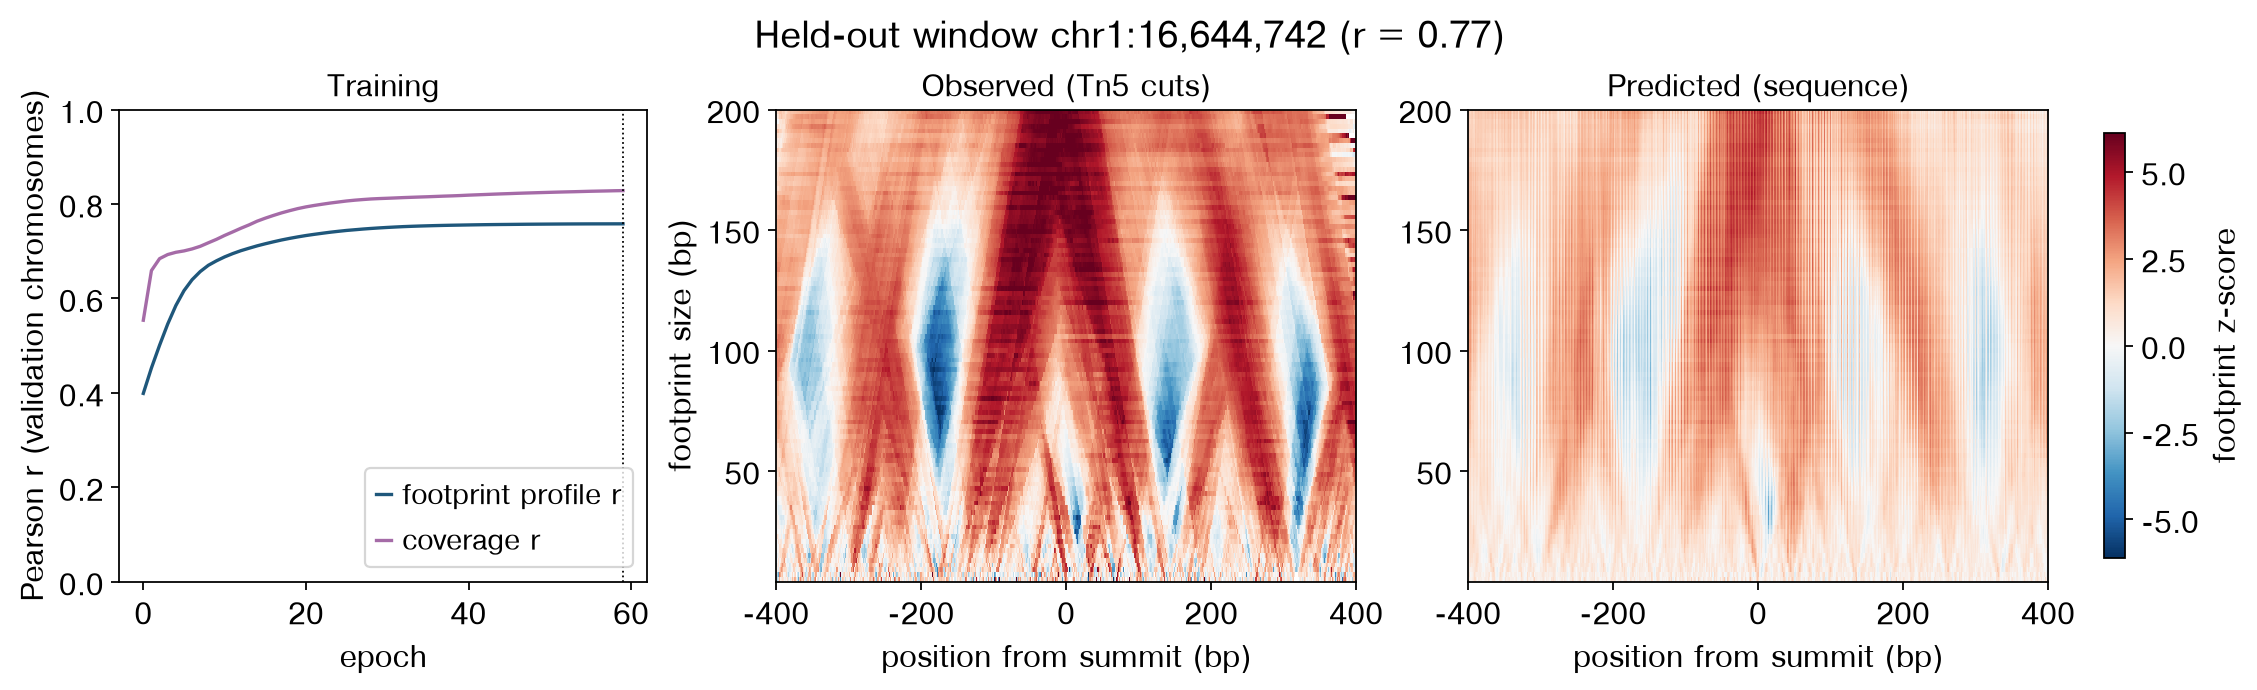

In [5]:
best_epoch = int(hist.valid_loss.idxmin())
i = int(np.argsort(test.coverage[:, 0])[-50])          # a well-covered test peak
X, y = test.centred()[i]
with torch.no_grad():
    pred, _ = model(X[None].to(DEVICE))
obs = s2p.multiscaleFoot(y[None, 0].to(DEVICE), y[None, 1].to(DEVICE),
                         np.arange(2, 101), target_model.to(DEVICE))[0]
pred = pred[0].float().cpu().numpy(); obs = obs.cpu().numpy()
r = np.corrcoef(np.nan_to_num(obs).ravel(), pred.ravel())[0, 1]
chrom, summit = test.peaks.chrom[i], int(test.peaks.summit[i])

fig = plt.figure(figsize=(14, 4.2), layout='constrained')
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.1, 1.1])
a0 = fig.add_subplot(gs[0])
a0.plot(hist.epoch, hist.valid_profile_pearson, label='footprint profile r')
a0.plot(hist.epoch, hist.valid_coverage_pearson, label='coverage r')
a0.axvline(best_epoch, color='k', lw=0.8, ls=':')
a0.set_xlabel('epoch'); a0.set_ylabel('Pearson r (validation chromosomes)')
a0.set_ylim(0, 1); a0.legend(loc='lower right'); a0.set_title('Training')
ext = [-400, 400, 4, 200]                               # 800 bp; footprint sizes 4-200 bp
vm = np.nanpercentile(np.abs(obs), 99)
for k, (M, t) in enumerate(((obs, 'Observed (Tn5 cuts)'), (pred, 'Predicted (sequence)'))):
    ax = fig.add_subplot(gs[k + 1])
    im = ax.imshow(M, aspect='auto', origin='lower', cmap='RdBu_r', vmin=-vm, vmax=vm,
                   extent=ext, interpolation='nearest')
    ax.set_title(t); ax.set_xlabel('position from summit (bp)')
    if k == 0:
        ax.set_ylabel('footprint size (bp)')
fig.colorbar(im, ax=ax, shrink=0.9, label='footprint z-score')
fig.suptitle(f'Held-out window {chrom}:{summit:,} (r = {r:.2f})')
plt.show()

## Part 5 · One LoRA state per cell type

LoRA freezes the bulk model and adds a low-rank update to every
convolution. A small network generates the update from a cell type's
embedding (its mean iterative-LSI coordinates), so one backbone serves all
seven cell types. A coverage covariate (each cell type's log cuts in
peaks) is absorbed first, because a footprint score grows with depth and
the cell types differ eight-fold in depth.

The fine-tuning windows are the 8,000 strongest peaks plus, for each cell
type, the 1,500 strongest peaks it called: every (peak, cell type) pair is
one training example. This light LoRA (rank 8, hidden width 64) takes
about 30 minutes on an H100; scPrinter's defaults (rank 32, width 256) are
`add_lora(emb, coverages=cov)` and `fit(..., lr=3e-5, accumulate=8,
coverage_warming=5)`.

In [6]:
%%time
sel = [ranked.head(8000)]
for t in TYPES:
    sel.append(ranked[ranked['group'] == t].head(1500))
lora_peaks = (pd.concat(sel)[['chrom', 'summit', 'group']].drop_duplicates(['chrom', 'summit'])
                .reset_index(drop=True))
groups = [np.flatnonzero(ct == t) for t in TYPES]
per_type = windows(lora_peaks, groups)          # item = peak * 7 + cell type
tr7, va7, te7 = (per_type.split(folds[s]) for s in ('train', 'valid', 'test'))

lora_ckpt = WORK / f'lora_celltype_{N_BULK}_8000_1500.pt'
if lora_ckpt.exists():                           # the embedding the cached LoRA was trained with
    emb, cov = np.load(WORK / 'lora_emb.npy'), np.load(WORK / 'lora_cov.npy')
else:
    lsi = atac.obsm['X_iterative_lsi']
    emb = np.stack([lsi[g].mean(0) for g in groups])
    emb = ((emb - emb.mean(0)) / emb.std(0)).astype(np.float32)
    cov = np.log10(per_type.coverage.sum(0))[:, None]
    cov = ((cov - cov.mean()) / cov.std()).astype(np.float32)
    np.save(WORK / 'lora_emb.npy', emb); np.save(WORK / 'lora_cov.npy', cov)
lora = copy.deepcopy(model).cpu().add_lora(emb, coverages=cov, rank=8, hidden_dim=64)
if lora_ckpt.exists():
    lora.load_state_dict(torch.load(lora_ckpt, map_location='cpu'))
else:
    res = s2p.fit(lora, tr7, va7, epochs=8, patience=3, lr=1e-4, coverage_warming=2,
                  num_workers=8, device=DEVICE, target_model=target_model)
    lora = res.model
    torch.save(lora.state_dict(), lora_ckpt)
lora = lora.to(DEVICE).eval()
print(f'{len(lora_peaks):,} peaks x {len(TYPES)} cell types = {len(per_type):,} windows')
metrics_lora = s2p.evaluate(lora, te7, target_model=target_model, device=DEVICE)
print('test chromosomes, each cell type with its own state:',
      {k: round(v, 3) for k, v in metrics_lora.items()})

15,686 peaks x 7 cell types = 109,774 windows


test chromosomes, each cell type with its own state: {'loss': 1.154, 'profile_pearson': 0.566, 'footprint_pearson': 0.72, 'coverage_pearson': 0.851}
CPU times: user 3min 4s, sys: 3min 6s, total: 6min 11s
Wall time: 6min 5s


**One held-out peak in three cell types.** The peak below is on a test
chromosome and is open mainly in CD14 monocytes. The top row is the
footprint each cell type's own cuts give (PRINT's score, from that cell
type alone); the bottom row is what the LoRA model predicts from the
sequence, conditioned on that cell type.

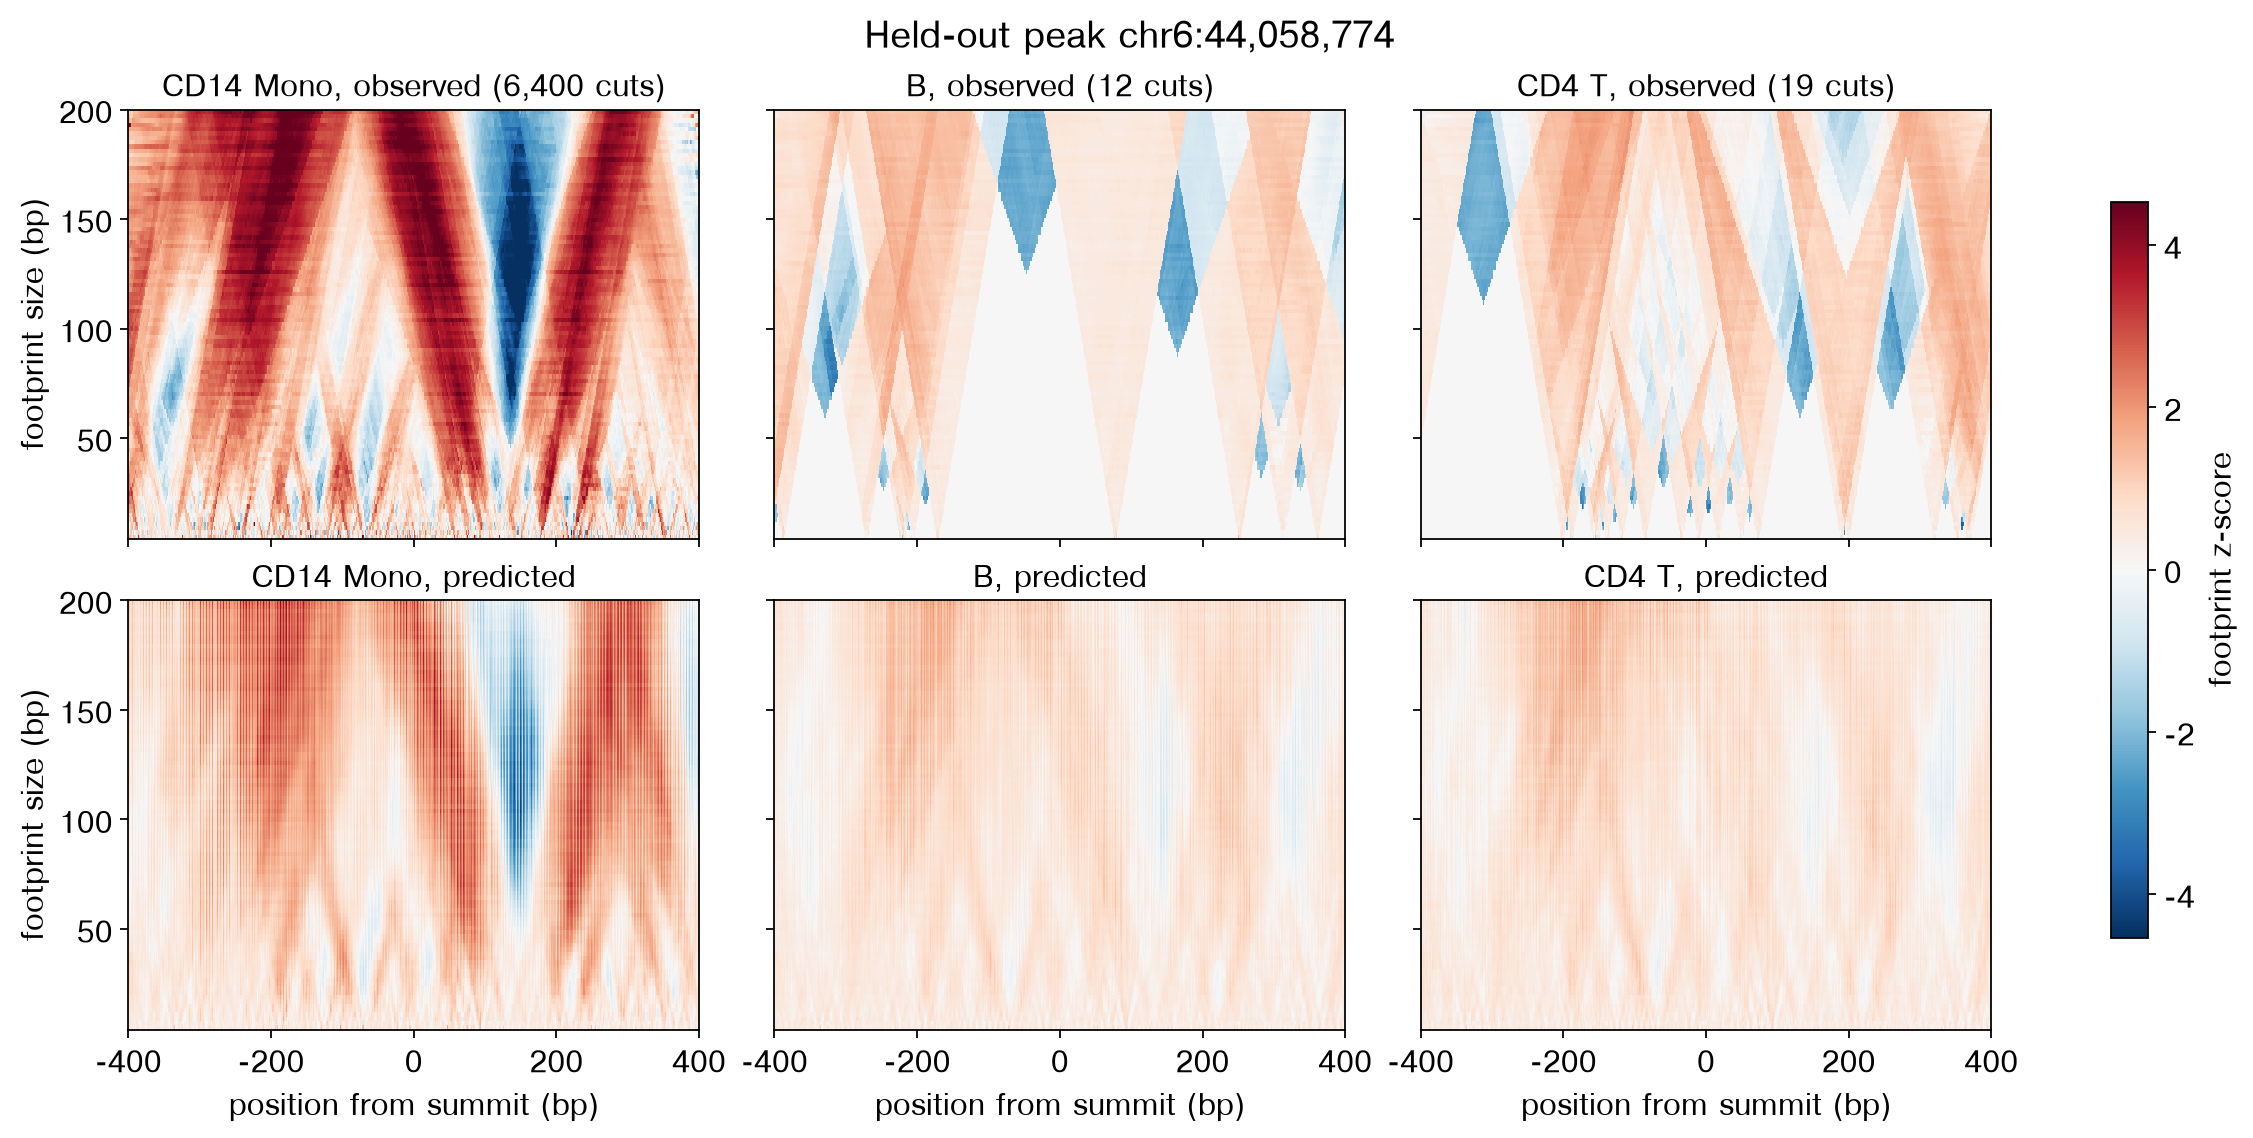

In [7]:
SHOW = ['CD14 Mono', 'B', 'CD4 T']
cov_t = te7.coverage                                   # [test peaks, cell types]: cuts per window
g_m, g_t = TYPES.index('CD14 Mono'), TYPES.index('CD4 T')
spec = np.log2((cov_t[:, g_m] + 10) / (cov_t[:, g_t] + 10))
ok = cov_t[:, g_m] >= np.quantile(cov_t[:, g_m], 0.9)
p = int(np.argmax(np.where(ok, spec, -np.inf)))       # deep in monocytes, low in CD4 T cells
cen = te7.centred()
obs, pred = [], []
with torch.no_grad():
    for t in SHOW:
        g = TYPES.index(t)
        X, y, _ = cen[p * len(TYPES) + g]
        obs.append(s2p.multiscaleFoot(y[None, 0].to(DEVICE), y[None, 1].to(DEVICE), np.arange(2, 101),
                                      target_model.to(DEVICE))[0].cpu().numpy())
        pred.append(lora(X[None].to(DEVICE), cells=torch.tensor([g], device=DEVICE))[0][0].float().cpu().numpy())
chrom, summit = te7.peaks.chrom[p], int(te7.peaks.summit[p])

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True, layout='constrained')
vm = np.nanpercentile(np.abs(np.stack(obs)), 99)
for j, t in enumerate(SHOW):
    for i, (M, kind) in enumerate(((obs[j], 'observed'), (pred[j], 'predicted'))):
        ax = axes[i, j]
        im = ax.imshow(np.nan_to_num(M), aspect='auto', origin='lower', cmap='RdBu_r', vmin=-vm, vmax=vm,
                       extent=[-400, 400, 4, 200], interpolation='nearest')
        ax.set_title(f'{t}, {kind}' + (f' ({int(cov_t[p, TYPES.index(t)]):,} cuts)' if i == 0 else ''))
        if i == 1:
            ax.set_xlabel('position from summit (bp)')
        if j == 0:
            ax.set_ylabel('footprint size (bp)')
fig.colorbar(im, ax=axes, shrink=0.8, label='footprint z-score')
fig.suptitle(f'Held-out peak {chrom}:{summit:,}')
plt.show()

## Part 6 · TF binding scores at marker promoters

`tf_binding` turns the model into a binding score at every base:

1. DeepLIFT/SHAP attributions (through gReLU) of two outputs, the coverage
   and the TF-sized footprints, for each cell type's state;
2. each attribution track is put on a common scale (median and 5-95%
   range over a sample of peaks, as scPrinter does);
3. scPrinter's two published TF-binding networks, trained on ChIP-seq,
   read the tracks and give a binding probability per base.

The scale comes from 300 random peaks in all seven states, so scores are
comparable across cell types and windows. These are the seven promoter
windows of scPrinter's PBMC tutorial.

In [8]:
%%time
samp = peaks.sample(300, random_state=0).reset_index(drop=True)
NORM = s2p.tf_binding(lora, s2p.one_hot_regions(FASTA, samp, length=model.dna_len),
                      states=list(range(len(TYPES)))).norm

LOCI = pd.DataFrame([
    ('SPI1',   'monocytes, B', 'chr11', 47378230, 47379030),
    ('CD14',   'monocytes',    'chr5',  140633035, 140633835),
    ('CD79A',  'B cells',      'chr19', 41876833, 41877633),
    ('CD3D',   'T cells',      'chr11', 118342294, 118343094),
    ('MPO',    'myeloid',      'chr17', 58281312, 58282112),
    ('ITGAM',  'myeloid',      'chr16', 31259594, 31260394),
    ('CX3CR1', 'monocytes',    'chr3',  39281281, 39282081),
], columns=['gene', 'marker of', 'chrom', 'start', 'end'])
loci_tfbs = s2p.tf_binding(lora, s2p.one_hot_regions(FASTA, LOCI, length=model.dna_len),
                           states=list(range(len(TYPES))), regions=LOCI, norm=NORM)
# strongest binding in each window, per cell type
pd.DataFrame(loci_tfbs.score.max(-1).T, index=LOCI.gene, columns=TYPES).round(2)

CPU times: user 26min 29s, sys: 2.12 s, total: 26min 31s
Wall time: 5min 45s


,CD14 Mono,CD16 Mono,DC,B,CD4 T,CD8 T,NK
gene,,,,,,,
SPI1,0.75,0.68,0.54,0.51,0.29,0.31,0.28
CD14,0.57,0.51,0.40,0.20,0.14,0.12,0.07
CD79A,0.34,0.22,0.20,0.21,0.17,0.16,0.16
CD3D,0.50,0.42,0.45,0.56,0.71,0.71,0.55
MPO,0.41,0.34,0.39,0.08,0.04,0.05,0.06
ITGAM,0.84,0.79,0.66,0.73,0.35,0.36,0.20
CX3CR1,0.51,0.46,0.62,0.39,0.08,0.06,0.08


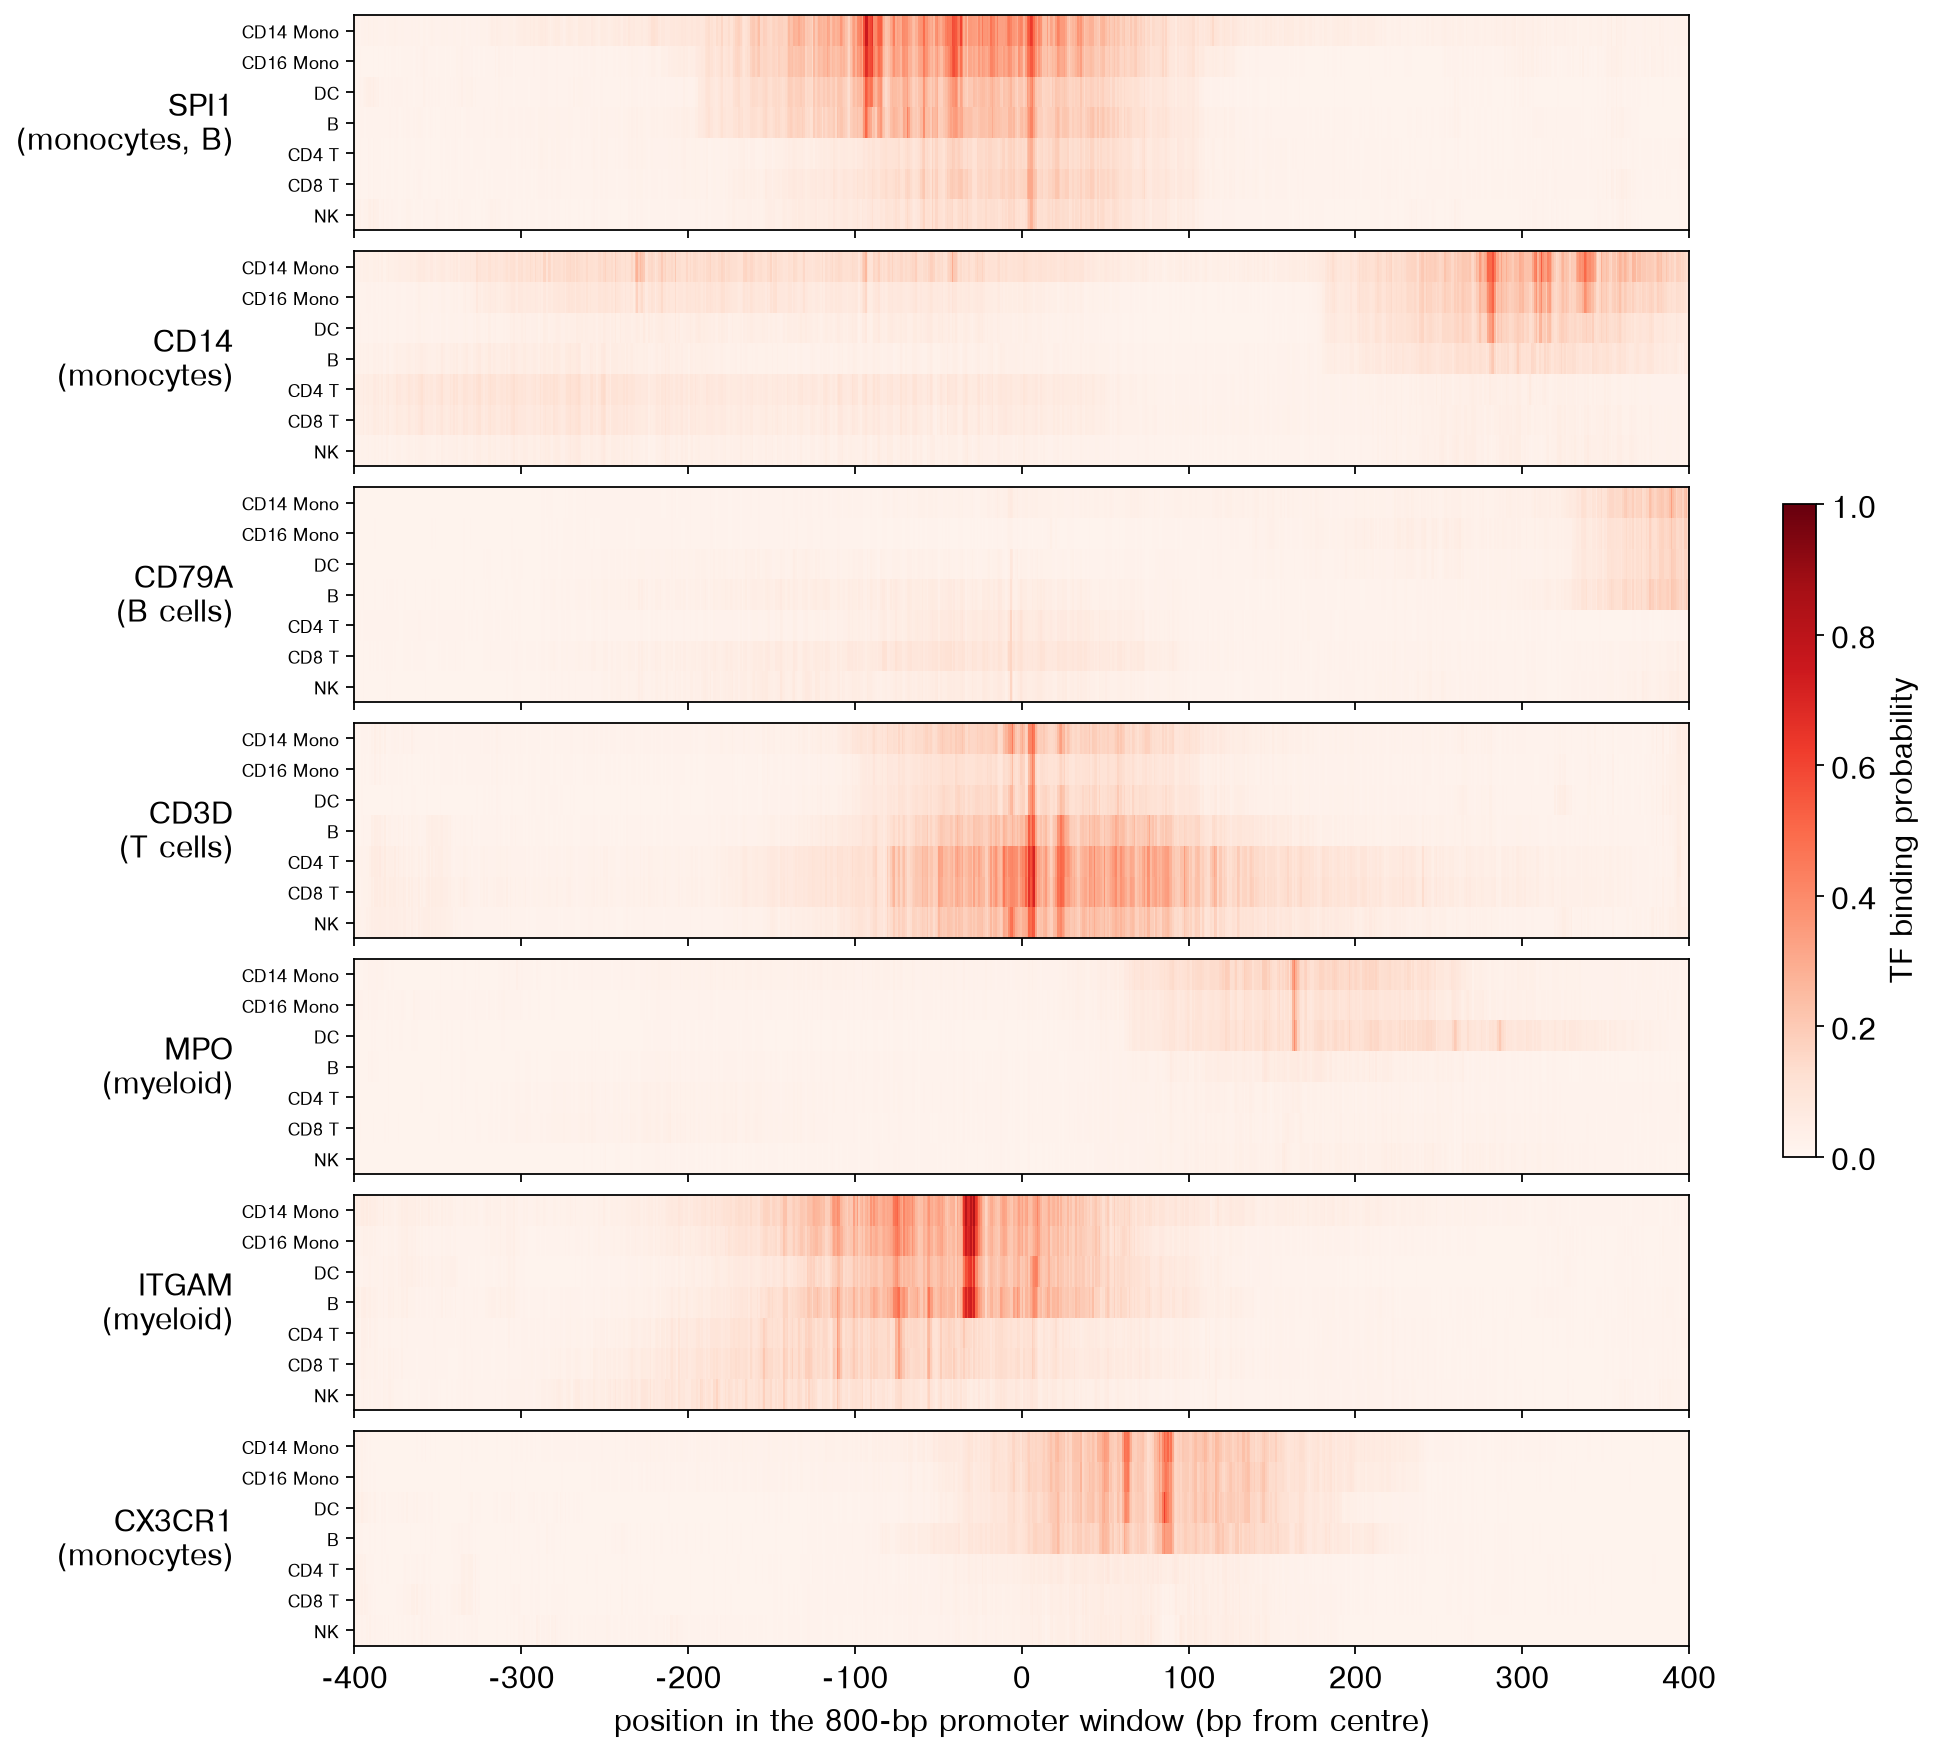

In [9]:
fig, axes = plt.subplots(len(LOCI), 1, figsize=(12, 1.55 * len(LOCI)), sharex=True, layout='constrained')
for ax, (k, row) in zip(axes, LOCI.iterrows()):
    im = ax.imshow(loci_tfbs.score[:, k], aspect='auto', cmap='Reds', vmin=0, vmax=1,
                   extent=[-400, 400, len(TYPES) - 0.5, -0.5], interpolation='nearest')
    ax.set_yticks(range(len(TYPES)), TYPES, fontsize=8)
    ax.set_ylabel(f"{row.gene}\n({row['marker of']})", rotation=0, ha='right', va='center')
axes[-1].set_xlabel('position in the 800-bp promoter window (bp from centre)')
fig.colorbar(im, ax=axes, shrink=0.4, label='TF binding probability')
plt.show()

At six of the seven promoters, binding follows the cells that use the gene:

* **SPI1** (PU.1, expressed in myeloid and B cells) is bound over the
  100 bp left of the window centre in both monocyte types, DCs and B cells
  (strongest base 0.51-0.75) and much less in T and NK cells (0.28-0.31).
* **CD14**: a bound stretch near the right end of the window appears in
  monocytes and DCs (0.40-0.57) and not in lymphocytes (0.07-0.20).
* **CD3D** is bound most in CD4 and CD8 T cells (0.71).
* **MPO** and **CX3CR1** are bound in myeloid cells (0.34-0.62) and hardly
  in T and NK cells (0.08 or less); **ITGAM** in myeloid cells (0.66-0.84),
  but also in B cells (0.73).
* **CD79A** is the exception: binding is weak in every cell type (0.34 or
  less) and not highest in B cells.

scPrinter's tutorial picks, for each promoter, the pseudobulks with the
strongest binding; here each cell type is one LoRA state, and B cells
(735 cells) are one of the smaller training sets.

## Part 7 · Binding of one TF across cell types

A TF's binding in a cell type is read at its motif sites: the score is the
highest per-base binding probability over the site. Motif sites of
CEBPA, SPI1 (PU.1), PAX5, EBF1, RUNX3 and TBX21 (T-bet), plus CTCF as a
control (a TF bound in every cell type), are found with MOODS (`hint_match_motifs`,
JASPAR 2024, p < 10⁻⁴) in the 500 strongest peaks of each cell type
(3,500 peaks), and every site is scored in all seven cell types.
This takes about an hour on an H100 (3,500 windows × 7 states × 2
outputs of DeepLIFT/SHAP).

In [10]:
%%time
MEME = WORK / 'JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt'
if not MEME.exists():
    import urllib.request
    urllib.request.urlretrieve('https://jaspar.elixir.no/download/data/2024/CORE/' + MEME.name, MEME)
jaspar = {k.split()[1].upper(): v for k, v in epi.models.grelu.read_meme(MEME).items()}
TFS = ['CEBPA', 'SPI1', 'PAX5', 'EBF1', 'RUNX3', 'TBX21', 'CTCF']
site_peaks = pd.concat([ranked[ranked['group'] == t].head(500) for t in TYPES]).reset_index(drop=True)
sites = epi.tl.hint_match_motifs(site_peaks[['chrom', 'start', 'end']],
                                 {tf: (jaspar[tf] * 100).round().tolist() for tf in TFS}, FASTA, fpr=1e-4)
# each site's window: the peak it was found in
key = pd.Series(np.arange(len(site_peaks)),
                index=pd.MultiIndex.from_frame(site_peaks[['chrom', 'start']]))
pk_start = sites.merge(site_peaks[['chrom', 'start', 'end']].rename(columns={'start': 'ps', 'end': 'pe'}),
                       on='chrom')
pk_start = pk_start[(pk_start.start >= pk_start.ps) & (pk_start.end <= pk_start.pe)]
pk_start = pk_start.drop_duplicates(['chrom', 'start', 'end', 'name', 'strand'])
sites = pk_start.assign(window=[key[(c, s)] for c, s in zip(pk_start.chrom, pk_start.ps)]) \
                .drop(columns=['ps', 'pe']).reset_index(drop=True)

ckpt_tfbs = WORK / 'tfbs_sites_500.npy'
if ckpt_tfbs.exists():
    site_tfbs = s2p.TFBindingTracks(score=np.load(ckpt_tfbs).astype(np.float32),
                                    states=list(range(len(TYPES))), regions=site_peaks, norm=NORM)
else:
    site_tfbs = s2p.tf_binding(lora, s2p.one_hot_regions(FASTA, site_peaks, length=model.dna_len),
                               states=list(range(len(TYPES))), regions=site_peaks, norm=NORM)
    np.save(ckpt_tfbs, site_tfbs.score.astype(np.float16))
scores = site_tfbs.site_scores(sites)
scores.columns = TYPES
sites = pd.concat([sites, scores], axis=1)
sites.groupby('name')[TYPES].mean().reindex(TFS).round(3).assign(sites=sites['name'].value_counts())

CPU times: user 626 ms, sys: 2.27 s, total: 2.9 s
Wall time: 2.97 s


,CD14 Mono,CD16 Mono,DC,B,CD4 T,CD8 T,NK,sites
name,,,,,,,,
CEBPA,0.399,0.359,0.169,0.097,0.108,0.109,0.096,508
SPI1,0.358,0.322,0.280,0.277,0.199,0.192,0.147,2603
PAX5,0.229,0.190,0.157,0.180,0.217,0.213,0.171,234
EBF1,0.158,0.133,0.114,0.145,0.153,0.155,0.120,858
RUNX3,0.135,0.114,0.150,0.135,0.221,0.242,0.213,725
TBX21,0.115,0.101,0.088,0.106,0.141,0.156,0.133,631
CTCF,0.255,0.210,0.192,0.237,0.278,0.275,0.217,871


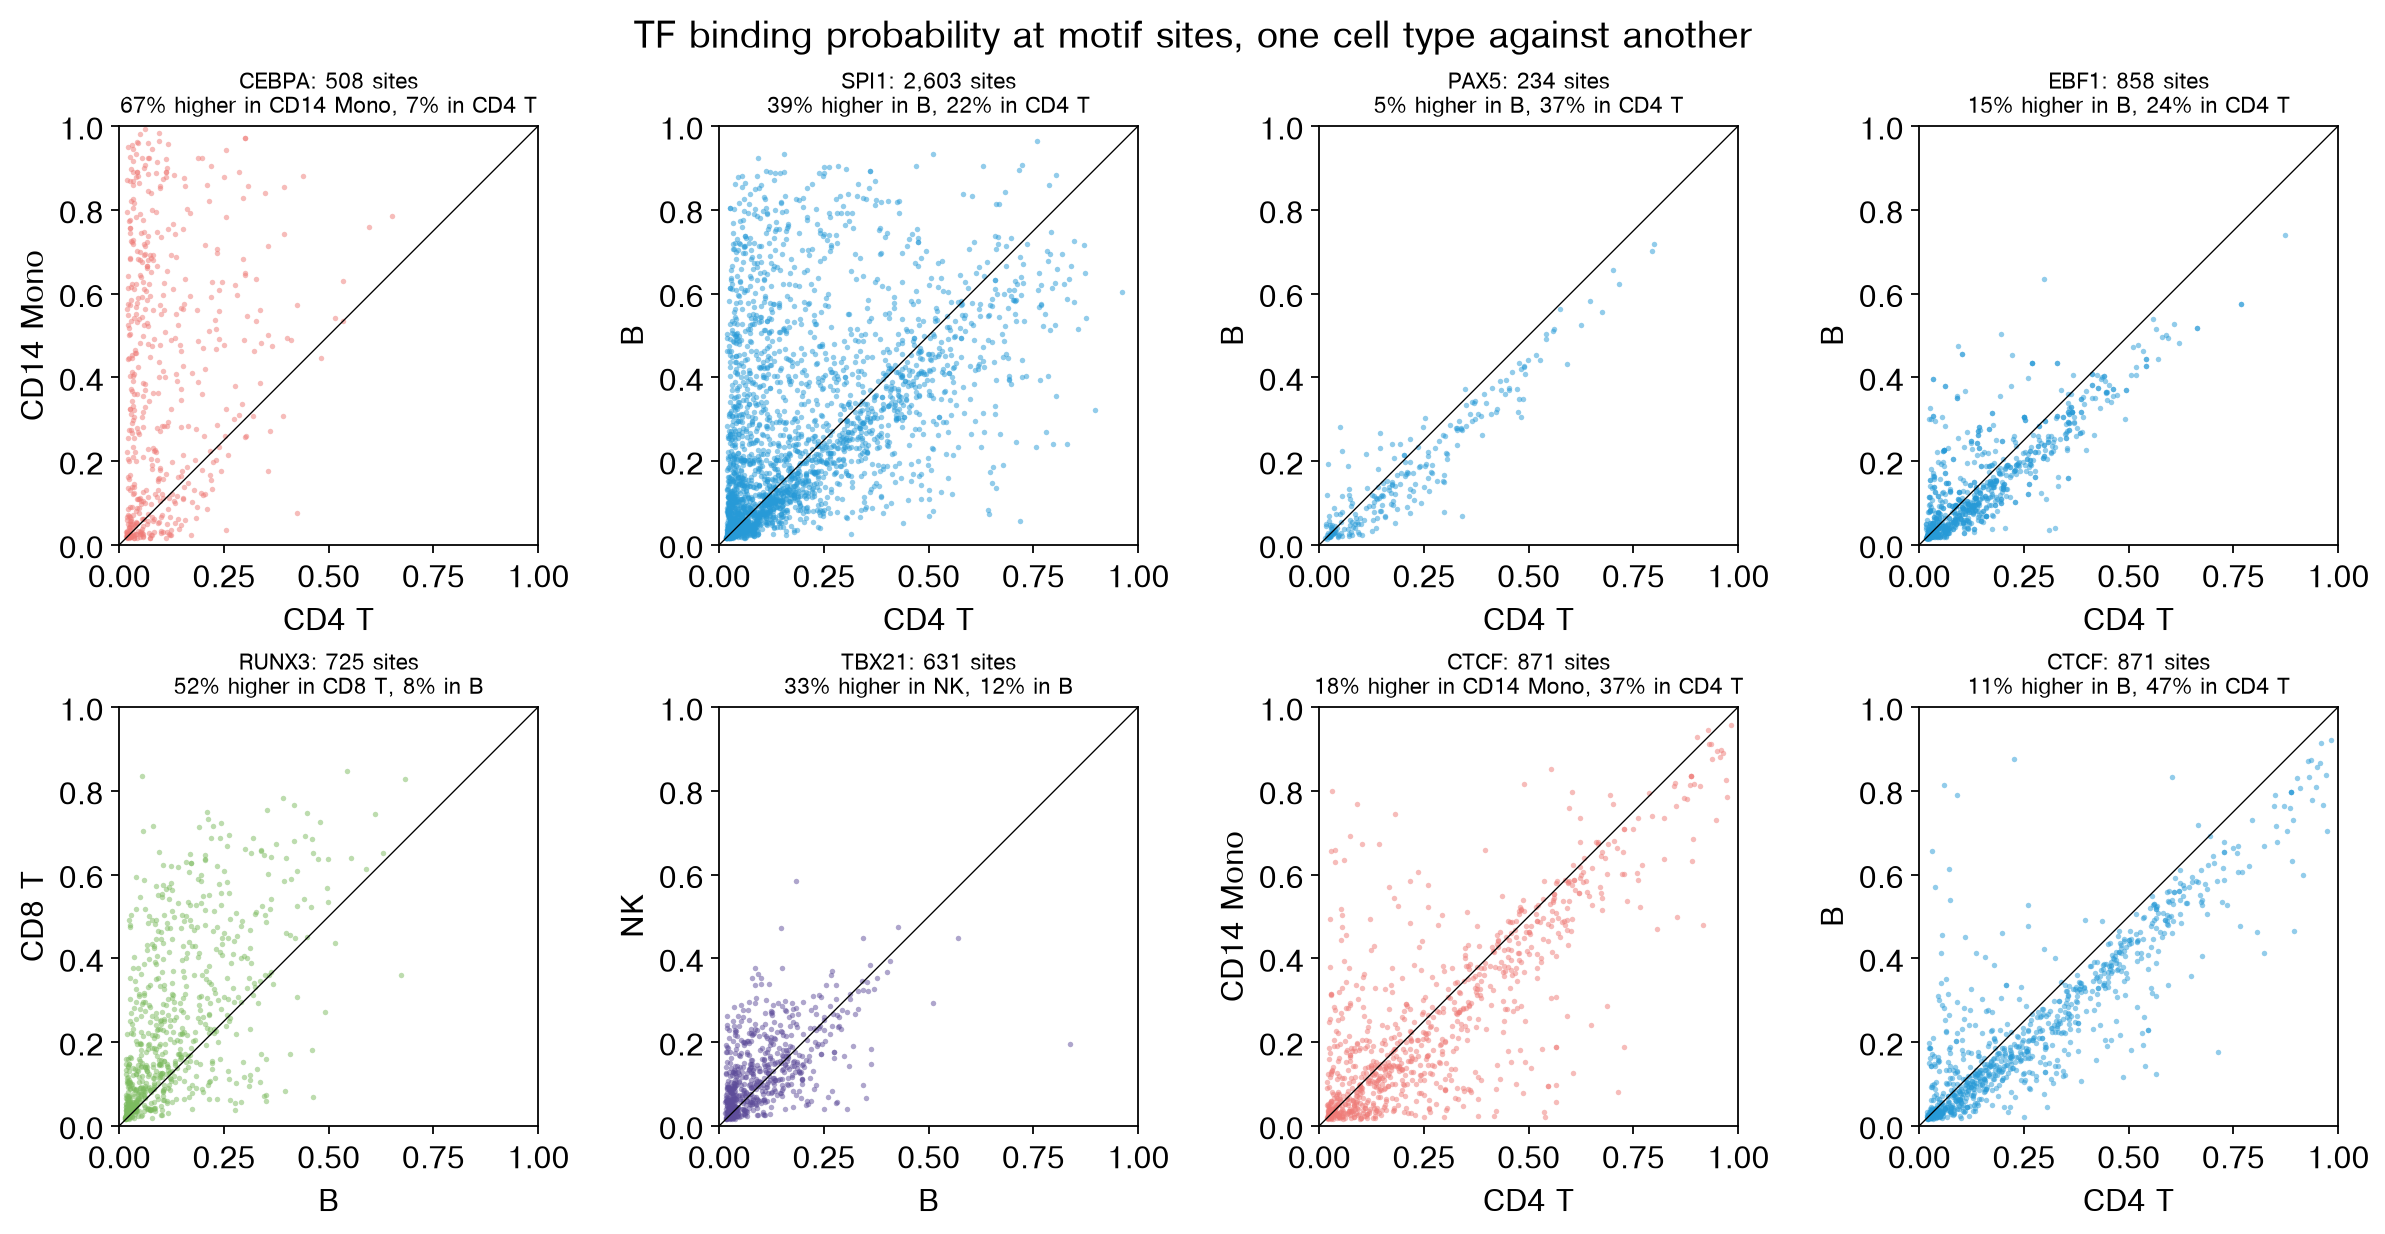

In [11]:
PAIRS = [('CEBPA', 'CD4 T', 'CD14 Mono'), ('SPI1', 'CD4 T', 'B'), ('PAX5', 'CD4 T', 'B'),
         ('EBF1', 'CD4 T', 'B'), ('RUNX3', 'B', 'CD8 T'), ('TBX21', 'B', 'NK'),
         ('CTCF', 'CD4 T', 'CD14 Mono'), ('CTCF', 'CD4 T', 'B')]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.6), layout='constrained')
for ax, (tf, a, b) in zip(axes.ravel(), PAIRS):
    d = sites[sites['name'] == tf]
    diff = d[b] - d[a]
    ax.scatter(d[a], d[b], s=6, lw=0, alpha=0.5, color=TCOL[b], rasterized=True)
    ax.plot([0, 1], [0, 1], color='k', lw=0.6)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
    ax.set_xlabel(f'{a}'); ax.set_ylabel(f'{b}')
    ax.set_title(f'{tf}: {len(d):,} sites\n{(diff > 0.05).mean():.0%} higher in {b}, '
                 f'{(diff < -0.05).mean():.0%} in {a}', fontsize=10)
fig.suptitle('TF binding probability at motif sites, one cell type against another')
plt.show()

Read every panel against the two CTCF panels. CTCF binds its sites in
all of these cell types, yet its scores are not symmetric: 37% of its
sites score higher in CD4 T cells than in monocytes (18% the other way),
and 47% higher in CD4 T than in B cells (11% the other way). The LoRA
states differ in overall level, and the B-cell state scores lower in
general. Comparing each TF's mean score ratio with CTCF's ratio for the
same two cell types (table above) removes that offset:

| TF | cell types | mean ratio | CTCF ratio |
|---|---|---|---|
| CEBPA | CD14 Mono / CD4 T | 3.7 | 0.92 |
| SPI1 | B / CD4 T | 1.39 | 0.85 |
| RUNX3 | CD8 T / B | 1.79 | 1.16 |
| TBX21 | NK / B | 1.25 | 0.92 |
| EBF1 | B / CD4 T | 0.95 | 0.85 |
| PAX5 | B / CD4 T | 0.83 | 0.85 |

* **CEBPA** is the clearest case: 67% of its 508 sites score higher in CD14
  monocytes than in CD4 T cells and 7% lower, as in scPrinter's tutorial.
* **SPI1 (PU.1)**, **RUNX3** and **TBX21 (T-bet)** are bound more where they
  are expressed: B cells over T cells, CD8 T over B cells, NK over B cells,
  well beyond the CTCF offset.
* **PAX5** and **EBF1**, the B-cell factors, follow the CTCF offset (EBF1
  at most slightly above it): the model does not resolve their B-cell
  binding. [t_print_footprint](t_print_footprint.ipynb) finds the same with
  footprints read from cuts, and scPrinter names the reasons: TFs with weak
  footprints or few sites are learned poorly, and related TFs share motifs.

The scores come from sequence, so every site gets one in every cell type,
including the small ones; how well a cell type's state is learned still
depends on its cells, which the CTCF panels make visible.

## Summary

| | |
|---|---|
| Data | 10x PBMC 10k Multiome ATAC, 9,341 cells in seven cell types (Seurat-WNN labels) |
| Peaks | `epi.single.call_peaks(groupby='celltype')`: 138,986 summit-centred peaks |
| Bulk model | scPrinter's architecture, 40,000 peaks, fold 0; test chromosomes: footprint profile r 0.76, coverage r 0.83 |
| LoRA | one state per cell type (rank 8); test chromosomes, own state: footprint profile r 0.57 (each cell type has a fraction of the cuts), coverage r 0.85 |
| TF binding | `s2p.tf_binding(model, onehot, states=...)`: per-base binding probability per cell type; marker promoters follow their cell types at 6 of 7; CEBPA, SPI1, RUNX3 and TBX21 sites are bound more where the TF is expressed; PAX5 and EBF1 are not resolved |
| More | attributions and motif discovery for this model and ChromBPNet: [t_sequence_attribution](t_sequence_attribution.ipynb); motif delta effects: `s2p.delta_effects` |